# Analytical and symbolic reconstructors at one wavelength

**Goal.** A reconstructor that is an analytical expression of moderate
complexity: a function of the field sampled at the lantern's 19 output
positions that returns each petal piston, without the hundreds to thousands
of degrees of freedom of the polynomial models, or the tens of thousands of
the MLPs. This is the 800 nm, +-300 nm case of `workbench.ipynb` Part A, on
the 50000-sample dataset (`data/ml/single_800nm_50k.npz`): fit on rows
0-36000, model selection on 36000-40000, validation on 40000-50000.

The answer, in short:

- **The forward map is exactly analytical.** With piston-only aberrations
  and monochromatic light, every output power is a Hermitian quadratic form
  in the six petal phasors. A closed form with 619 physical constants
  reproduces the camera signals to numerical precision (section 1).
- **Its inversion is an excellent reconstructor** (section 7). Gauss-Newton
  converges within 5 iterations for 99.95% of cases from a good first
  estimate, and a staged procedure solves every case. The result is exact
  without noise, 0.9 nm RMS with 1% noise, and has no gross errors up to
  3% noise. The 619 constants can be calibrated from about 100 known
  configurations.
- **Explicit expressions over the full +-300 nm range are much harder**
  (sections 3-4). The inverse of the trigonometric map is complicated. Even
  with symmetry-adapted features, polynomials need about 200 terms per
  phasor for 10-24 nm, and symbolic regression (PySR, Operon) stays near
  80 nm at moderate complexity.
- **Over smaller ranges explicit expressions work** (sections 5-6). At
  +-100 nm PySR finds expressions with 4-8 constants and about 40 nodes
  that reach 2.6-4.2 nm, against 6-8 nm for a linear map. Below +-50 nm
  even the linear reconstructor is accurate to 1-2%.
- **The limit is the aberrations the model leaves out** (section 7e).
  Low-order residuals (tip/tilt, focus, astigmatism) leak into the piston
  estimates at about 0.6 nm per nm RMS, for the analytical reconstructor and
  the MLP alike.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import pandas as pd
import ml_reconstruct as ml
from ml_reconstruct import forward as fw, symbolic as sy, petals
from ml_reconstruct.simulate import bp
from sklearn.linear_model import RidgeCV

LAM, FIT, ES, VA = 800.0, slice(0, 36000), slice(36000, 40000), slice(40000, 50000)
cache = ml.ModelCache("data/ml/cache_symbolic")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
ds = ml.LanternDataset.load("data/ml/single_800nm_50k.npz")
S, P, xy = ds.signals, ds.coeff, ds.core_xy
p800 = bp.get_simulation_parameters(3, 0.8)
ifunc = bp.load_ifunc(p800["ifunc_file"]); bp.center_ifunc_mask(ifunc)
geom = petals.petal_geometry(ifunc.mask_inf_func, np.asarray(ifunc.influence_function))
linear = cache("linear-pistons", lambda: RidgeCV(alphas=np.logspace(-6, 2, 9)).fit(S[FIT], P[FIT]))
print(f"{len(S)} samples, {S.shape[1]} cores; linear reconstructor: RMSE "
      f"{ml.rmse_nm(linear.predict(S[VA]), P[VA]).round(1)} nm")

[cache] loaded linear-pistons
50000 samples, 19 cores; linear reconstructor: RMSE [ 94.  105.9 115.9 107.9  93.4] nm


## 1. The forward map is exactly analytical

The field at an output core is a linear function of the input field, and
with piston-only aberrations the input field is a sum over the six petals of
exp(i phi_j) times a fixed petal pattern. So the core power is

N_c = a_c + sum_{j<k} [A_cjk cos D_jk + B_cjk sin D_jk],  with  D_jk = 2 pi (p_j - p_k) / lambda

(the reference petal has p = 0). That is linear in 30 trigonometric features
z, with 31 constants per core. The camera signals are normalised by the
coupled power, which is a form of the same kind, so

s_c = N_c / (1 + q . z),

with 19 x 31 + 30 = 619 constants. Given the pistons it is linear in the
constants, and one least-squares solve fits it.

This is not a shortcut that applies the piston phases at the lantern input.
Every signal here comes from the full simulation: pupil phase -> zero-padded
FFT -> PSF field at the lantern input -> projection on the lantern modes ->
cbeam propagation -> camera windows. The closed form follows from linearity:

- **PSF field:** it is the sum over the petals of exp(i phi_j) times the
  fixed focal-plane field E_j(u) of petal j alone.
- **Lantern output:** the lantern is linear in its input field, so its
  output is the sum of exp(i phi_j) times petal j's response O_j(x).
- **Signals:** a camera window integrates |output|^2, which gives the sum
  over j, k of exp(i (phi_j - phi_k)) times the integral of O_j O_k*.

The constants therefore absorb the petal PSFs, the lantern's mode projection
and propagation, and the camera windows. Here they are fitted to simulated
data; they could equally be computed directly, by propagating the six
single-petal PSF fields. The form is exact because the aberrations are
pistons. Other aberrations change the petal fields themselves, which section
7e tests.

In [3]:
chan = ml.LanternDataset.load("data/ml/spectral_41wl.npz"); w800 = int(np.argmin(np.abs(chan.wavelengths_nm - LAM)))
models = {"camera signals, ratio form (619)": (fw.fit_forward(P[:10000], S[:10000], LAM), S, P),
          "camera signals, numerator only (589)": (fw.fit_forward(P[:10000], S[:10000], LAM, normalised=False), S, P),
          "channel powers, +-5 um (589)": (fw.fit_forward(chan.coeff[:10000], chan.signals[:10000, w800], LAM,
                                                           normalised=False), chan.signals[:, w800], chan.coeff)}
for name, (m, Sx, Px) in models.items():
    r = Sx[VA] - m(Px[VA])
    print(f"{name:40s} relative residual RMS on the validation rows: {np.sqrt(np.mean(r ** 2)) / Sx[VA].std():.1e}")
model = models["camera signals, ratio form (619)"][0]

camera signals, ratio form (619)         relative residual RMS on the validation rows: 1.9e-08
camera signals, numerator only (589)     relative residual RMS on the validation rows: 4.7e-02
channel powers, +-5 um (589)             relative residual RMS on the validation rows: 2.3e-08


The ratio form fits to numerical precision. The channel powers (fraction of
the incident light, with no normalisation) are exactly the numerator form.
So the lantern at one wavelength is completely described, for pistons, by
how strongly each core interferes each pair of petals:

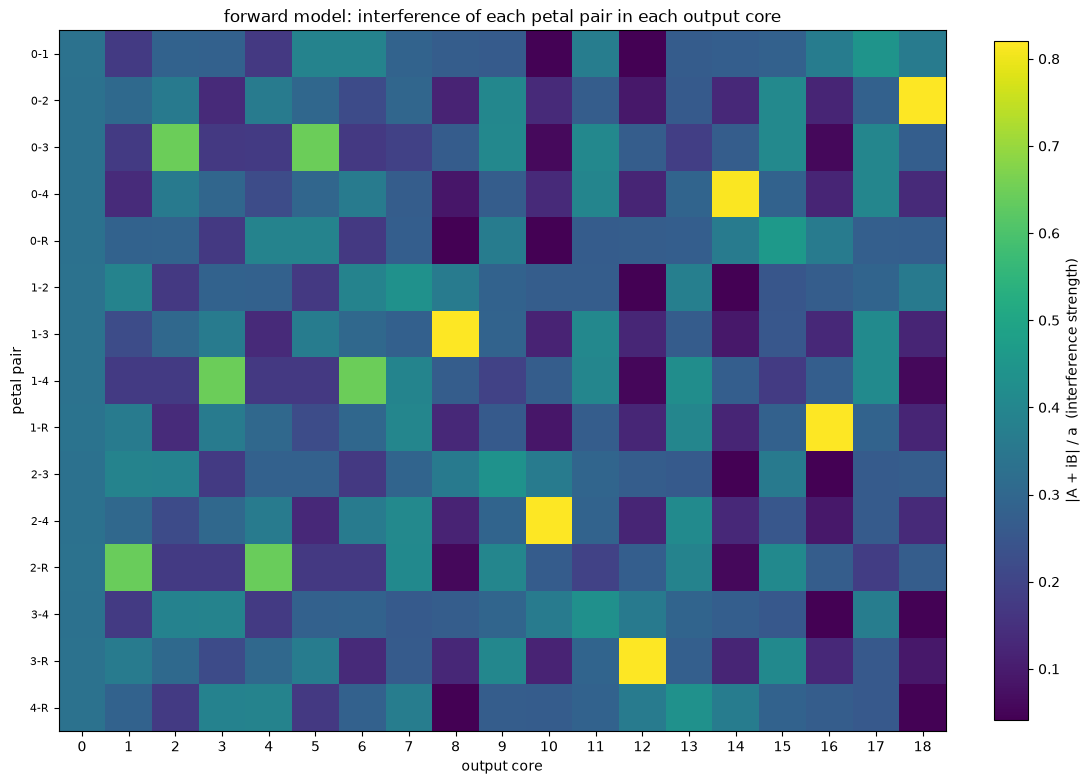

In [4]:
fw.plot_coefficients(model)

## 2. Symmetry-adapted features

For explicit expressions, the representation of the input matters more than
the engine. Two choices:

- **Inputs.** The 19 cores lie on rings of a hexagonal grid: the centre, and
  three rings of 6 (at a, sqrt(3) a and 2 a). The angular harmonics of each
  ring, sum_c s_c exp(-i m theta_c) for m = 0..3, re-express the 19 signals
  as 19 numbers ordered by symmetry: moments of the output field. For piston
  k they are taken in the frame of the bisector of petal k and the
  reference, oriented so that petal k is on the positive side. Their real
  parts are even, and their imaginary parts odd, under the mirror that swaps
  petal k and the reference. Pistons related by the mirror (0 and 4, 1 and
  3) then see the same problem, and can share one expression.
- **Targets.** Each piston's phasor (sin, cos)(2 pi p_k / lambda), decoded
  with atan2. This is unique within +-lambda/2, and it saves the expression
  from having to contain an arctangent.

In [5]:
ring, theta = sy.rings(xy)
print("cores per ring:", np.bincount(ring))
for k in range(5):
    a, o = sy.pair_frame(geom, k)
    print(f"piston {k}: petal at {np.degrees(sy.petal_angles_mesh(geom)[k]):7.1f} deg, frame {np.degrees(a):7.1f} deg, "
          f"orientation {o:+.0f}")
F_k = {k: sy.harmonic_features(S, xy, *sy.pair_frame(geom, k)) for k in range(5)}
print("features:", F_k[0][1])

cores per ring: [1 6 6 6]
piston 0: petal at   120.0 deg, frame    89.8 deg, orientation +1
piston 1: petal at   180.0 deg, frame   119.8 deg, orientation +1
piston 2: petal at  -119.8 deg, frame   -30.1 deg, orientation -1
piston 3: petal at   -59.8 deg, frame    -0.1 deg, orientation -1
piston 4: petal at     0.0 deg, frame    29.8 deg, orientation -1
features: ['c0', 'r1m0', 'r1m1re', 'r1m1im', 'r1m2re', 'r1m2im', 'r1m3re', 'r2m0', 'r2m1re', 'r2m1im', 'r2m2re', 'r2m2im', 'r2m3re', 'r3m0', 'r3m1re', 'r3m1im', 'r3m2re', 'r3m2im', 'r3m3re']


## 3. Explicit polynomial models of the phasors

How complex does an explicit map have to be? Polynomials in the harmonic
features, fitted to the phasors of each piston, with all degree-1 terms
(ridge), or a budget of K terms per phasor chosen by OMP. "dof" counts the
fitted constants of the two phasors of one piston.

In [6]:
configs = [("linear", 1, None), ("quadratic, K = 20", 2, 20), ("quadratic, K = 60", 2, 60),
           ("cubic, K = 200", 3, 200)]
rows = []
for name, deg, K in configs:
    for k in range(5):
        F, T = F_k[k][0], sy.phasor_targets_k(P, k, LAM)
        m = cache(f"phasor-k{k}-d{deg}-K{K}", lambda: sy.fit_phasor_poly(F[FIT], T[FIT], deg, K))
        pr = sy.predict_phasor_poly(m, F[VA])
        e = sy.decode(pr[:, 0], pr[:, 1], LAM) - P[VA, k]
        rows.append(dict(model=name, piston=k, dof=sy.phasor_poly_dof(m), rmse=np.sqrt(np.mean(e ** 2))))
poly = pd.DataFrame(rows).pivot(index="model", columns="piston", values=["rmse", "dof"]).round(1)
display(poly.loc[[c[0] for c in configs]])

[cache] loaded phasor-k0-d1-KNone
[cache] loaded phasor-k1-d1-KNone
[cache] loaded phasor-k2-d1-KNone
[cache] loaded phasor-k3-d1-KNone
[cache] loaded phasor-k4-d1-KNone
[cache] loaded phasor-k0-d2-K20
[cache] loaded phasor-k1-d2-K20
[cache] loaded phasor-k2-d2-K20
[cache] loaded phasor-k3-d2-K20
[cache] loaded phasor-k4-d2-K20
[cache] loaded phasor-k0-d2-K60
[cache] loaded phasor-k1-d2-K60
[cache] loaded phasor-k2-d2-K60
[cache] loaded phasor-k3-d2-K60
[cache] loaded phasor-k4-d2-K60
[cache] loaded phasor-k0-d3-K200
[cache] loaded phasor-k1-d3-K200
[cache] loaded phasor-k2-d3-K200
[cache] loaded phasor-k3-d3-K200
[cache] loaded phasor-k4-d3-K200


rmse                               dof                \
piston                0      1      2      3     4      0      1      2   
model                                                                     
linear             84.4  115.7  129.4  118.3  82.6   40.0   40.0   40.0   
quadratic, K = 20  59.4   74.0   67.2   80.9  58.6   42.0   42.0   42.0   
quadratic, K = 60  41.4   49.4   43.9   54.0  42.9  122.0  122.0  122.0   
cubic, K = 200     24.3   20.1   10.4   21.0  22.9  402.0  402.0  402.0   

                                 
piston                 3      4  
model                            
linear              40.0   40.0  
quadratic, K = 20   42.0   42.0  
quadratic, K = 60  122.0  122.0  
cubic, K = 200     402.0  402.0

For reference, the best cubic model of `workbench.ipynb` (Part A, A4): OMP
with 1282 terms per piston on the degree-3 monomials of the standardised
Zernike projection. It regresses the pistons directly, was trained on the
8000 training rows of the 10k dataset (the first 8000 rows here), and is
scored on the same 10000 validation rows as everything else in this
notebook:

In [7]:
p_wb, dof_wb = sy.workbench_zern_omp(S[:8000], P[:8000], xy, S[VA])
e_wb = np.abs(p_wb - P[VA])
print(f"workbench cubic OMP, K = 1282: RMSE {ml.rmse_nm(p_wb, P[VA]).round(2)} nm, median {np.median(e_wb):.2f} nm, "
      f"99th percentile {np.percentile(e_wb, 99):.1f} nm; {dof_wb} constants")

workbench cubic OMP, K = 1282: RMSE [8.8  7.85 8.32 8.04 8.83] nm, median 4.73 nm, 99th percentile 29.3 nm; 6406 constants


A linear map of the moments is far off (80-130 nm), and the error falls only
slowly with the number of terms: about 200 terms per phasor give 10-24 nm,
and the workbench's 1282 terms per piston 8.4 nm (6406 constants).
The inverse of the trigonometric forward map is genuinely complicated. Each
phasor depends on the others through the interference terms of all the
petal pairs.

## 4. Symbolic regression

`scripts/symbolic_sr.py` (run by `scripts/run_symbolic_sr.sh`) searches for
explicit expressions of the 19 harmonic features for the sine and cosine of
each class of piston:

- **classes:** opposite (piston 2), adjacent (0 and 4 pooled) and
  next-but-one (1 and 3 pooled);
- **operators:** +, -, x, / and the square;
- **data:** 10000 fit rows per piston;
- **engines:** **Operon** (pyoperon: multi-objective, the whole
  accuracy-vs-length front) and **PySR** (its hall of fame over
  complexities, 10 minutes per target).

For each class the sine and cosine expressions are paired at every total
complexity, and the pair with the best held-out piston RMSE is kept. The
front is scored on the validation rows. "constants" counts the fitted
numbers in both expressions.

In [8]:
SR_DIR = "data/ml/symbolic"
fronts = {}
for engine in ("operon", "pysr"):
    res = sy.load_sr(SR_DIR, engine)
    for cls in sy.CLASSES:
        if (cls, "sin") in res and (cls, "cos") in res:
            fronts[f"{engine}, {cls}"] = sy.sr_front(res, cls, LAM)
for label, f in fronts.items():
    print(label); display(f[["complexity", "constants", "es_rmse", "val_rmse", "val_median"]].round(2).tail(8))

operon, opposite


,complexity,constants,es_rmse,val_rmse,val_median
18,66,34,81.17,83.75,47.85
19,68,35,81.13,83.65,47.83
20,74,38,81.10,86.05,22.97
21,76,39,79.88,84.49,22.81
22,84,43,79.73,84.77,22.22
23,86,44,79.20,81.69,22.38
24,94,48,78.76,81.44,22.11
25,96,49,78.70,82.09,21.77


operon, adjacent


,complexity,constants,es_rmse,val_rmse,val_median
33,86,44,80.25,83.43,38.87
34,88,45,79.44,82.31,38.37
35,90,46,79.34,81.94,38.18
36,92,47,79.04,81.60,37.68
37,94,48,78.97,81.48,37.53
38,98,50,78.78,81.08,37.20
39,100,51,78.29,80.78,36.66
40,104,53,78.29,81.07,36.39


operon, next


,complexity,constants,es_rmse,val_rmse,val_median
12,36,19,103.12,103.83,57.88
13,38,20,102.85,103.06,57.78
14,40,21,101.65,103.03,57.13
15,42,22,101.09,102.50,56.56
16,44,23,99.40,101.17,56.31
17,62,32,98.68,99.61,54.79
18,64,33,97.53,99.36,54.32
19,66,34,96.93,98.15,54.14


... (2 outputs left out)

pysr, adjacent


,complexity,constants,es_rmse,val_rmse,val_median
14,45,8,94.90,96.72,55.20
15,47,8,94.25,95.89,61.04
16,48,11,93.29,94.50,55.24
17,52,9,91.03,92.55,54.56
18,54,10,90.77,91.67,54.31
19,56,10,90.25,92.43,54.64
20,78,11,88.21,91.47,47.23
21,82,12,87.98,91.58,47.61


pysr, next


,complexity,constants,es_rmse,val_rmse,val_median
9,20,5,112.95,113.68,62.78
10,22,6,111.54,112.50,62.91
11,24,6,108.85,109.73,64.36
12,26,6,107.59,108.93,63.88
13,34,7,107.50,108.36,59.37
14,36,8,106.06,107.09,59.61
15,40,9,105.12,106.13,59.20
16,42,9,102.43,103.08,57.14


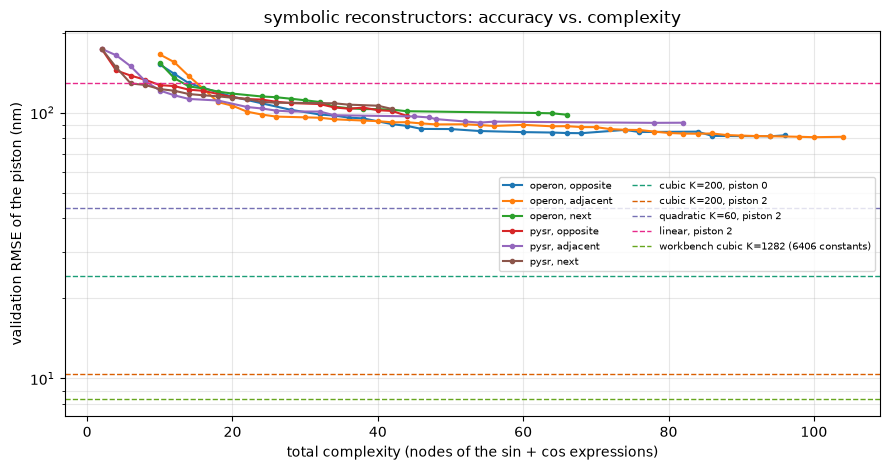

In [9]:
refs = {f"cubic K=200, piston {k}": poly.loc["cubic, K = 200", ("rmse", k)] for k in (0, 2)}
refs.update({f"quadratic K=60, piston 2": poly.loc["quadratic, K = 60", ("rmse", 2)],
             "linear, piston 2": poly.loc["linear", ("rmse", 2)],
             "workbench cubic K=1282 (6406 constants)": ml.rmse_nm(p_wb, P[VA]).mean()})
sy.plot_sr_fronts(fronts, refs)

In [10]:
for label, f in fronts.items():
    if len(f):
        r = f[f.complexity <= 60].iloc[-1] if (f.complexity <= 60).any() else f.iloc[0]
        print(f"{label}: complexity {r.complexity}, {r.constants} constants, validation RMSE {r.val_rmse:.1f} nm")
        print(f"   sin = {r.sin_expr}\n   cos = {r.cos_expr}\n")

operon, opposite: complexity 60, 31 constants, validation RMSE 84.4 nm
   sin = ((-0.0737) + ((-0.2652) * (((((((-0.4781) * r1m2re) * (((((-1.0634) * r3m1im) - ((-0.5535) * r3m3re)) - 0.6931) - (((-0.3532) * r3m2im) * (2.3026 * r2m1re)))) + (((-0.5535) * r2m2re) * (((((-0.7796) * r3m1im) - ((-1.0300) * r3m3re)) - (0.4837 * r1m1im)) - (0.7071 * r1m3re)))) - (((-0.3532) * r3m2im) * (1.2753 * r2m1re))) - ((-1.4069) * r2m1im)) - ((((-0.5679) + (1.3007 * r1m2re)) * (((-0.1968) * r1m0) * (((-1.2354) * r3m3re) + (1.4142 * r2m1im)))) - ((((0.3171 * r3m2re) * ((((-1.0240) * r3m1im) - ((-1.1552) * r3m3re)) - ((-1.1091) * r2m1im))) + ((0.7071 * r3m1im) + ((-1.0300) * r3m3re))) - (0.7179 * r1m3re))))))
   cos = (0.3031 + (0.7503 * (0.3054 * r2m2re)))

operon, adjacent: complexity 60, 31 constants, validation RMSE 89.9 nm
   sin = (0.0392 + (0.1491 * (((1.2578 * r1m1im) * (0.7071 * r3m1re)) - ((((((((1.8832 * r2m2im) - ((-1.4987) * r1m1im)) + ((1.7725 * r2m1im) + ((-2.9123) * r3m2im))) + (2.2232 * 

Over the full +-300 nm range neither engine finds a compact inverse. At
complexity 60-100 both stay near 80 nm (R^2 0.5-0.9 on the phasors), barely
better than the linear map of section 3 and worse than its 60-term
quadratic polynomials. With 19 measurements and an inverse that undoes a
trigonometric map folding over +-0.75 pi of phase, there is no short closed
form to find.

## 5. Where explicit expressions work: the capture range

The difficulty is the range. Over +-300 nm the phases reach +-0.75 pi and the
forward map folds strongly. Near the flat wavefront it is close to linear.
The exact forward model of section 1 is a noise-free simulator for any
range, so it can show how compact explicit reconstructors fare as the range
shrinks. The models: linear in the 19 signals, and sparse quadratic (OMP,
K terms per piston), fitted to the pistons directly. A closed-loop SCAO
petal sensor sees residuals of tens of nm, so the small ranges are the
relevant ones there.

In [11]:
scan = sy.range_scan(model, [25, 50, 100, 200, 300])
display(scan.round(3))

,range_nm,linear (100 dof),quadratic K=10 (55 dof),quadratic K=30 (155 dof)
0,25,0.199,0.354,0.057
1,50,1.075,1.484,0.404
2,100,6.249,7.737,3.120
3,200,35.163,37.109,22.838
4,300,100.192,103.803,81.201


Up to +-50 nm a linear reconstructor is already accurate to about 1-2% of
the range, and a quadratic correction with 30 terms per piston improves it
3-4 times. Beyond about +-100 nm explicit low-order expressions fail.
Acquisition over the full range needs the inversion of section 7.

## 6. Symbolic regression at +-100 nm

At +-100 nm the linear reconstructor is clearly imperfect (about 6 nm), but
a compact nonlinear correction should exist. Here symbolic regression
regresses the piston directly: same features and classes as in section 4,
noise-free data from the forward model (`scripts/symbolic_sr.py --range
100`).

In [12]:
fronts100 = {}
for engine in ("operon", "pysr"):
    for cls, r in sy.load_sr_direct(SR_DIR, engine, 100).items():
        fronts100[f"{engine}, {cls}"] = sy.sr_front_direct(r)
for label, f in fronts100.items():
    print(label); display(f[["complexity", "constants", "es_rmse", "val_rmse"]].round(2).tail(8))

operon, opposite


,complexity,constants,es_rmse,val_rmse
9,23,12,3.24,3.19
10,28,15,3.15,3.20
11,30,16,3.04,3.04
12,32,17,2.88,2.92
13,34,18,2.87,2.91
14,35,19,2.85,2.86
15,37,20,2.85,2.86
16,40,22,2.79,2.85


operon, adjacent


,complexity,constants,es_rmse,val_rmse
20,38,20,25.74,25.97
21,42,22,24.51,24.85
22,45,24,24.36,24.64
23,51,27,24.28,24.42
24,57,30,24.12,24.28
25,59,31,23.86,24.10
26,61,32,23.75,23.99
27,63,33,23.68,23.93


operon, next


,complexity,constants,es_rmse,val_rmse
23,44,23,2.44,2.46
24,45,23,2.43,2.45
25,46,24,2.35,2.34
26,48,25,2.33,2.33
27,51,26,2.20,2.27
28,55,28,2.17,2.23
29,57,29,2.16,2.20
30,59,30,2.14,2.18


... (6 outputs left out)

pysr, next


,complexity,constants,es_rmse,val_rmse
14,27,6,3.23,3.27
15,29,6,3.19,3.19
16,31,6,3.02,3.04
17,33,6,2.96,2.96
18,35,6,2.81,2.82
19,39,6,2.66,2.67
20,43,8,2.62,2.64
21,45,8,2.49,2.52


pysr, adjacent-0


,complexity,constants,es_rmse,val_rmse
15,28,6,7.50,7.58
16,29,3,7.02,6.91
17,31,3,6.17,6.05
18,33,3,5.26,5.07
19,36,3,4.80,4.60
20,38,4,4.60,4.38
21,40,4,4.38,4.18
22,42,4,4.11,3.94


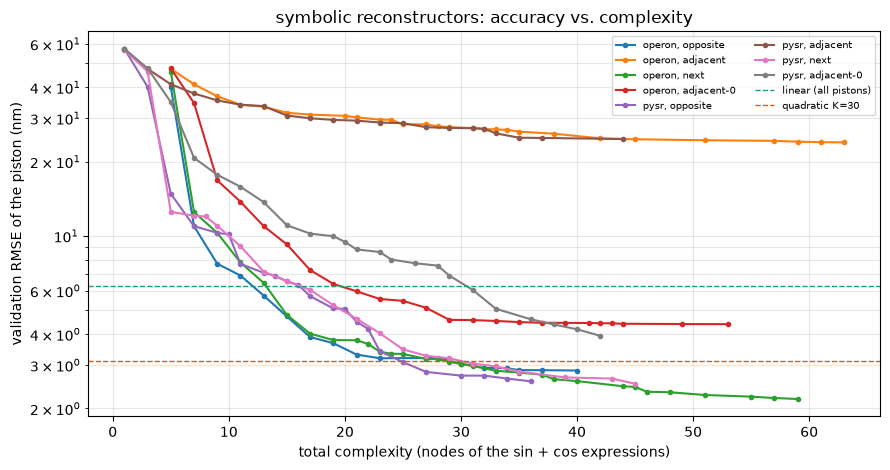

operon, opposite: complexity 40, 22 constants, RMSE 2.85 nm
   p = ((-6.1412) + (28.4979 * (((-0.0754) * r1m2re) - ((((((((1.8918 * r2m1im) + ((-1.4690) * r3m3re)) - (((-0.0754) * r2m1im) * (0.4343 * r3m2re))) - ((0.1477 * r1m0) ^ 2)) - (((-0.1224) * r1m2re) * (0.3183 * r1m1im))) - ((-0.2994) * r3m1im)) + ((0.1060 * r1m3re) - (((0.1060 * r1m3re) - ((0.1477 * r3m2im) ^ 2)) ^ 2))) + (((-0.1139) * r1m2re) * (((((-0.7122) * r3m3re) + (2.5282 * r2m1im)) + ((-0.2581) * r1m0)) + (0.5902 * c0)))))))

operon, adjacent: complexity 38, 20 constants, RMSE 25.97 nm
   p = (5.5111 + (14.4041 * ((((((0.1830 * r2m0) * ((((-2.1360) * r1m2re) + ((-2.9647) * r2m1re)) + (((-2.3027) * r1m2im) + ((-1.3398) * r2m1im)))) - (((-0.5415) * r2m1re) * (((-0.9893) * r1m2re) - (((1.1940 * r2m2im) + ((-2.1813) * r3m2im)) - (((-0.9322) * r3m2re) - ((-2.8419) * r1m2im)))))) + (((-2.0810) * r1m2im) + ((-1.3398) * r2m1im))) - ((((-0.7508) * r1m2re) + ((-1.3020) * r2m1re)) + (((-0.5548) * r1m1im) ^ 2))) + (0.4953 * r3m2im

In [13]:
refs100 = {"linear (all pistons)": scan.loc[scan.range_nm == 100, "linear (100 dof)"].item(),
           "quadratic K=30": scan.loc[scan.range_nm == 100, "quadratic K=30 (155 dof)"].item()}
sy.plot_sr_fronts(fronts100, refs100)
for label, f in fronts100.items():
    if len(f):
        r = f[f.complexity <= 40].iloc[-1] if (f.complexity <= 40).any() else f.iloc[0]
        print(f"{label}: complexity {r.complexity}, {r.constants} constants, RMSE {r.val_rmse:.2f} nm\n   p = {r.expression}\n")

At +-100 nm both engines find compact expressions:

| class | PySR | linear map of the features (20 constants) |
|---|---|---|
| opposite (piston 2) | 2.6 nm (8 constants, complexity 36) | 5.8 nm |
| next-but-one (1, 3) | 2.7 nm (6 constants, complexity 39) | 5.8 nm |
| adjacent (piston 0 alone) | 4.2 nm (4 constants, complexity 40) | 8.4 nm |

That is as good as the sparse quadratic polynomials (3.1 nm on average, 155
constants for the 5 pistons). Operon reaches similar errors with more
constants. The expressions are polynomials of low degree in a few of the
harmonic moments: mostly the m = 1 and m = 2 moments of the rings, which
carry the odd (sign-sensitive) part of the response.

The pooled "adjacent" class (pistons 0 and 4 together) fails (about 25 nm),
and that is a flaw of these features, not of the physics. The lantern is
mirror-symmetric to about 1%. But the m = 3 harmonic of the 6-core rings
keeps only its real part, which is close to zero and flips sign between the
two adjacent pistons' frames, while the information sits in the imaginary
part that was dropped. Fitted alone, piston 0 behaves like the other
classes. The next-but-one class pools correctly.

## 7. The analytical reconstructor: invert the forward model

The forward map s(p) is an exact closed form, so the reconstructor can be its
inversion: minimise |s - s(p)|^2 over the 5 pistons by Gauss-Newton,

p <- p + (J^T J)^-1 J^T (s - s(p)),     J = ds/dp (analytic, 19 x 5),

from a first estimate. Each iteration costs one evaluation of the closed
form and of its Jacobian, and a 5 x 5 solve: a few thousand floating-point
operations. The model has 619 physical constants.

### 7a. The closed form

For every output core c, with D_jk = 2 pi (p_j - p_k) / lambda and petal 5
(the reference) at p_5 = 0:

In [14]:
import sympy as sp
eq, p_sym, lam_sym = fw.sympy_generic()
display(eq)

Eq(s_c, (A_{c,01}*cos(2*pi*(p_0 - p_1)/lambda) + A_{c,02}*cos(2*pi*(p_0 - p_2)/lambda) + A_{c,03}*cos(2*pi*(p_0 - p_3)/lambda) + A_{c,04}*cos(2*pi*(p_0 - p_4)/lambda) + A_{c,05}*cos(2*pi*p_0/lambda) + A_{c,12}*cos(2*pi*(p_1 - p_2)/lambda) + A_{c,13}*cos(2*pi*(p_1 - p_3)/lambda) + A_{c,14}*cos(2*pi*(p_1 - p_4)/lambda) + A_{c,15}*cos(2*pi*p_1/lambda) + A_{c,23}*cos(2*pi*(p_2 - p_3)/lambda) + A_{c,24}*cos(2*pi*(p_2 - p_4)/lambda) + A_{c,25}*cos(2*pi*p_2/lambda) + A_{c,34}*cos(2*pi*(p_3 - p_4)/lambda) + A_{c,35}*cos(2*pi*p_3/lambda) + A_{c,45}*cos(2*pi*p_4/lambda) + B_{c,01}*sin(2*pi*(p_0 - p_1)/lambda) + B_{c,02}*sin(2*pi*(p_0 - p_2)/lambda) + B_{c,03}*sin(2*pi*(p_0 - p_3)/lambda) + B_{c,04}*sin(2*pi*(p_0 - p_4)/lambda) + B_{c,05}*sin(2*pi*p_0/lambda) + B_{c,12}*sin(2*pi*(p_1 - p_2)/lambda) + B_{c,13}*sin(2*pi*(p_1 - p_3)/lambda) + B_{c,14}*sin(2*pi*(p_1 - p_4)/lambda) + B_{c,15}*sin(2*pi*p_1/lambda) + B_{c,23}*sin(2*pi*(p_2 - p_3)/lambda) + B_{c,24}*sin(2*pi*(p_2 - p_4)/lambda) + B_{c,25

The fitted constants for the central core and for one core of the first
ring, keeping the six largest terms of the numerator and of the denominator
(the numerator relative to the core's constant term; pistons in nm). With
all the terms, the sympy expression reproduces the model to machine
precision.

In [15]:
for core in (0, 3):
    display(fw.sympy_forward(model, core, n_terms=6))
full = sp.lambdify(p_sym, fw.sympy_forward(model, 3, digits=15).rhs, "numpy")
print("full sympy expression of core 3 vs. the model:",
      f"{np.abs(full(*P[VA][:100].T) - model(P[VA][:100])[:, 3]).max() / S[:, 3].max():.1e} (relative)")

Eq(s_{0}, 0.001019*((0.336*cos(0.0025*pi*p_1) + 0.334*cos(0.0025*pi*p_2) + 0.334*cos(0.0025*pi*p_3) + 0.336*cos(pi*(0.0025*p_1 - 0.0025*p_2)) + 0.336*cos(pi*(0.0025*p_1 - 0.0025*p_3)) + 0.335*cos(pi*(0.0025*p_1 - 0.0025*p_4)) + 1)/(0.036*cos(0.0025*pi*p_1) + 0.036*cos(0.0025*pi*p_3) + 0.036*cos(pi*(0.0025*p_0 - 0.0025*p_2)) + 0.036*cos(pi*(0.0025*p_0 - 0.0025*p_4)) + 0.036*cos(pi*(0.0025*p_1 - 0.0025*p_3)) + 0.035*cos(pi*(0.0025*p_2 - 0.0025*p_4)) + 1)))

Eq(s_{3}, 0.001045*((0.323*sin(0.0025*pi*p_1) + 0.387*sin(0.0025*pi*p_4) + 0.322*sin(pi*(0.0025*p_1 - 0.0025*p_3)) - 0.388*sin(pi*(0.0025*p_3 - 0.0025*p_4)) + 0.59*cos(pi*(0.0025*p_1 - 0.0025*p_4)) - 0.302*cos(pi*(0.0025*p_2 - 0.0025*p_4)) + 1)/(0.036*cos(0.0025*pi*p_1) + 0.036*cos(0.0025*pi*p_3) + 0.036*cos(pi*(0.0025*p_0 - 0.0025*p_2)) + 0.036*cos(pi*(0.0025*p_0 - 0.0025*p_4)) + 0.036*cos(pi*(0.0025*p_1 - 0.0025*p_3)) + 0.035*cos(pi*(0.0025*p_2 - 0.0025*p_4)) + 1)))

full sympy expression of core 3 vs. the model: 3.0e-15 (relative)


The central core interferes the petal pairs only through cosines. It is
blind to the sign of the pistons, as its symmetry requires. The off-axis
cores carry the sine terms, and with them the sign information.

### 7b. Convergence: how many iterations?

From three first estimates: the linear reconstructor (100 constants), the
cubic phasor polynomial of section 3, and the 36000-sample MLP ensemble of
`workbench.ipynb` Part C. The first estimate brings the case into the
right basin; Gauss-Newton then converges quadratically.

[cache] loaded phasor-k0-d3-K200
[cache] loaded phasor-k1-d3-K200
[cache] loaded phasor-k2-d3-K200
[cache] loaded phasor-k3-d3-K200
[cache] loaded phasor-k4-d3-K200


,start,threshold_nm,<= 1 it,<= 2 it,<= 3 it,<= 5 it,<= 10 it,not in 15 it
0,linear,1.00,0.06,19.60,60.75,84.94,90.19,9.26
1,linear,0.01,0.00,0.22,27.84,79.94,90.09,9.27
2,cubic phasor poly,1.00,52.34,98.95,99.87,99.88,99.88,0.12
3,cubic phasor poly,0.01,0.05,72.68,99.38,99.88,99.88,0.12
4,MLP ensemble,1.00,99.76,99.91,99.93,99.97,99.97,0.03
5,MLP ensemble,0.01,94.03,99.80,99.92,99.95,99.97,0.03


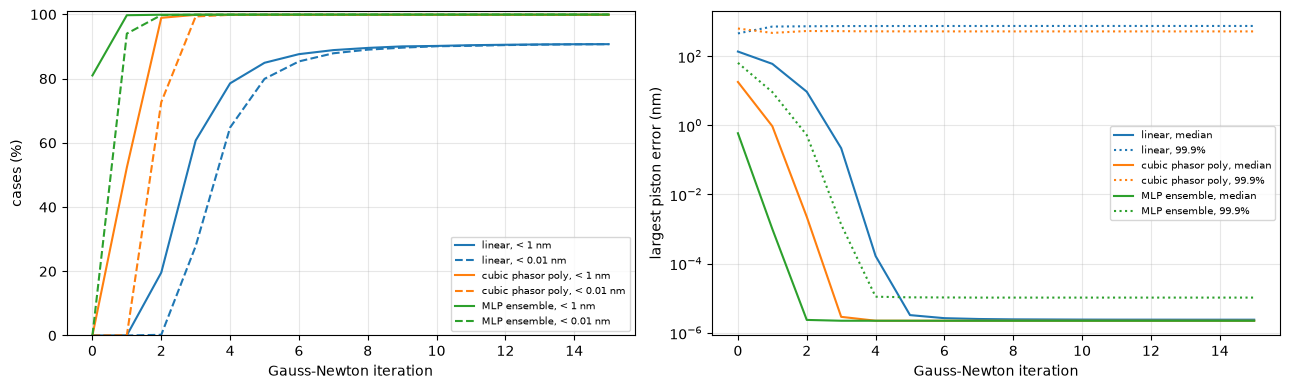

In [16]:
from ml_reconstruct.notebook import rescore_mlp
p_cubic = np.stack([sy.decode(*sy.predict_phasor_poly(cache(f"phasor-k{k}-d3-K200", None), F_k[k][0][VA]).T, LAM)
                    for k in range(5)], 1)
p_mlp = rescore_mlp([f"800nm-50k-d4w256-cos3e-4-e2000-n36000-s{s}" for s in range(5)], "data/ml/mlp_hpo", ds, VA, 36000)
starts = {"linear": linear.predict(S[VA]), "cubic phasor poly": p_cubic, "MLP ensemble": p_mlp}
traces = {name: fw.gn_trace(model, S[VA], p0, P[VA]) for name, p0 in starts.items()}
display(fw.convergence_table(traces).round(2))
fw.plot_convergence(traces)

### 7c. The reconstructor as a procedure, and its cost

A single start leaves a few cases in the wrong basin, but the residual
|s - s(p)| flags them: it is about 1e-11 when converged and about 1e-3
otherwise. So the reconstructor is a procedure (`forward.solve_staged`):

1. 5 iterations from the first estimate;
2. for the flagged cases, 8 iterations each from the estimate's twin T p,
   its sign flip -p, -T p and the flat wavefront (the usual wrong basins,
   `piston2.ipynb`);
3. random restarts, 8 iterations each, for whatever is left.

The table gives the share of cases each stage solved, and the worst-case
number of iterations.

In [17]:
T = petals.twin_matrix(geom["opposite"], geom["ref"])
rows = []
for name, p0 in starts.items():
    Ph, res, it, stage = fw.solve_staged(model, S[VA], p0, T, tol=1e-8)
    e = np.abs(Ph - P[VA]).max(1)
    rows.append(dict(start=name, **{f"solved in stage {k} %": 100 * np.mean(stage == k) for k in range(4)},
                     iterations_p99=np.percentile(it, 99), iterations_max=it.max(), max_error_nm=e.max()))
display(pd.DataFrame(rows).round(3))
print(f"one case, 5 iterations, numpy: {fw.time_single_case(model, S[40000], starts['linear'][0]):.0f} us")

,start,solved in stage 0 %,solved in stage 1 %,solved in stage 2 %,solved in stage 3 %,iterations_p99,iterations_max,max_error_nm
0,linear,76.75,9.54,13.71,0.0,253.0,1365,0.003
1,cubic phasor poly,99.88,0.02,0.10,0.0,5.0,461,0.000
2,MLP ensemble,99.94,0.05,0.01,0.0,5.0,69,0.000


one case, 5 iterations, numpy: 354 us


**Convergence.**

- **From the MLP ensemble:** 94% of cases are below 0.01 nm after 1
  iteration, 99.8% after 2 and 99.95% after 5.
- **From the cubic phasor polynomial:** 99.4% after 3 iterations.
- **From the linear reconstructor:** only 80% after 5, because a tenth of its
  estimates start in the wrong basin.

**The staged procedure solves every case** (no case is left in stage 3):

- **From the MLP ensemble:** 99.94% of cases need only the first 5
  iterations, and the worst case 69.
- **From the linear reconstructor:** 13.7% need random restarts, and the
  worst case about 1400 iterations.

**Cost.** One iteration costs about 75 us for a single case in numpy (Python
overhead), and about 4 us per case when 10000 cases are batched. In compiled
code it is a few thousand floating-point operations.

### 7d. Noise

Gaussian noise of standard deviation (level x mean signal) on every core,
inverted with `forward.invert` (the first estimate plus 32 random starts,
keeping the lowest residual).

,noise,rmse,median,p99,> 50 nm %
0,0.0000,"[0.0, 0.0, 0.0, 0.0, 0.0]",0.000001,0.000005,0.00
1,0.0001,"[0.009, 0.009, 0.009, 0.009, 0.009]",0.005865,0.025461,0.00
2,0.0010,"[0.093, 0.092, 0.092, 0.091, 0.092]",0.058756,0.255419,0.00
3,0.0100,"[0.908, 0.9, 0.915, 0.9, 0.921]",0.579823,2.537090,0.00
4,0.0300,"[2.718, 2.735, 2.796, 2.702, 2.738]",1.752291,7.632730,0.00
5,0.1000,"[9.273, 9.231, 9.429, 9.377, 9.375]",5.785505,26.232665,0.08
6,0.3000,"[40.576, 45.553, 43.332, 41.249, 43.465]",17.965035,105.887255,26.73


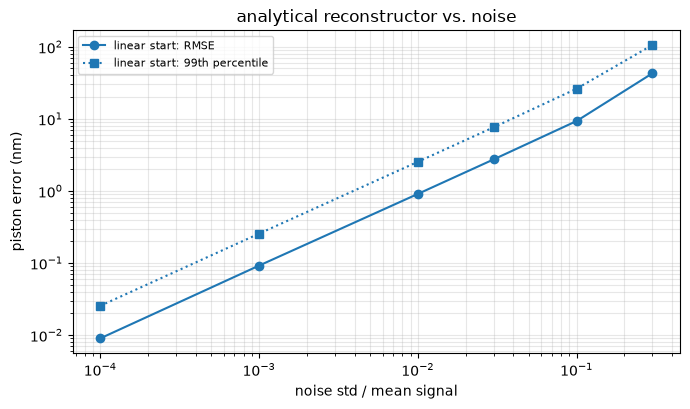

In [18]:
levels = [0.0, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1]
noise = {"linear start": fw.noise_scan(model, S[VA], P[VA], lambda Sx: linear.predict(Sx), levels)}
display(noise["linear start"])
fw.plot_noise_scan(noise)

The error grows linearly with the noise, about 0.9 nm RMS per 1% of noise,
up to 10% noise (9.3 nm, 0.08% of cases off by more than 50 nm). At 30% the
inversion breaks down: 27% gross errors, as the noise starts to move the
lowest residual into other basins.

### 7e. Aberrations the model does not describe

Pistons only enter the forward model. `scripts/symbolic_residuals.py`
simulates 2000 configurations with random pistons in +-300 nm plus random
low-order residuals (tip, tilt, focus, astigmatism) of 0-100 nm RMS in total,
measured exactly like the dataset (the same core centres). Each is
reconstructed by inverting the forward model, starting from the MLP
ensemble plus 32 random starts, and, for comparison, by the MLP ensemble
itself, also trained on pistons only. "model misfit" is the RMS difference
between the signals and the forward model at the true pistons, relative to
the signals' spread.

In [19]:
from ml_reconstruct.notebook import rescore_mlp_on
mlp_ids = [f"800nm-50k-d4w256-cos3e-4-e2000-n36000-s{s}" for s in range(5)]
rows = []
for level in (0, 5, 10, 25, 50, 100):
    with np.load(f"data/ml/symbolic/residuals_lo{level:g}.npz") as f:
        Sr, Cr = f["signals"], f["coeff"][:, :5]
    Pm = rescore_mlp_on(mlp_ids, "data/ml/mlp_hpo", ds, 36000, Sr)
    Ph, _, _ = fw.invert(model, Sr, Pm, n_starts=32)
    rows.append(dict(low_order_rms_nm=level, model_misfit=np.sqrt(np.mean((Sr - model(Cr)) ** 2)) / S.std(),
                     **{f"analytic {k}": v for k, v in fw.error_summary(Ph, Cr).items()},
                     **{f"MLP {k}": v for k, v in fw.error_summary(Pm, Cr).items()}))
display(pd.DataFrame(rows).round(3))

,low_order_rms_nm,model_misfit,analytic rmse,analytic median,analytic p99,analytic > 50 nm %,MLP rmse,MLP median,MLP p99,MLP > 50 nm %
0,0,0.000,"[0.0, 0.0, 0.0, 0.0, 0.0]",0.000,0.000,0.00,"[0.755, 0.664, 0.587, 0.592, 0.763]",0.266,2.305,0.0
1,5,0.034,"[3.715, 4.614, 4.617, 4.544, 3.611]",3.100,9.743,0.00,"[3.575, 4.29, 4.674, 4.211, 3.582]",2.912,9.803,0.0
2,10,0.068,"[7.437, 9.249, 9.245, 9.1, 7.245]",6.207,19.505,0.00,"[7.047, 8.508, 9.289, 8.365, 7.053]",5.783,19.286,0.0
3,25,0.170,"[18.787, 23.249, 23.254, 22.892, 18.177]",15.464,49.397,3.95,"[17.705, 21.267, 23.256, 21.089, 17.53]",14.372,48.174,3.9
4,50,0.337,"[46.128, 58.95, 67.059, 58.413, 46.371]",31.169,107.239,74.25,"[39.696, 47.067, 48.718, 50.091, 36.972]",28.608,111.896,67.6
5,100,0.653,"[126.711, 163.092, 145.85, 142.762, 134.412]",65.519,661.174,99.25,"[98.651, 122.476, 117.119, 120.548, 91.742]",58.143,466.658,97.7


Aberrations outside the model are the real limit. Low-order residuals leak
into the piston estimates at about 0.6 nm of median piston error per nm RMS
of residual: 3 nm at 5 nm RMS, 15 nm at 25 nm RMS. Gross errors (more than
50 nm) affect 4% of cases at 25 nm RMS and most of them at 50 nm. The MLP, trained on pistons only, degrades in the same way. This is a
property of piston-only reconstructors at one wavelength, not of the
inversion.

Two ways forward:

- **Keep the low-order modes small.** The SCAO loop has to correct them well
  below about 5 nm RMS.
- **Model them.** The closed form extends to them: to first order in small
  low-order coefficients c_m, petal j's focal-plane field is
  E_j + i sum_m c_m E_jm. The input is then still a fixed linear
  combination of petal-phasor-weighted patterns, and the signals a quadratic
  form in a larger set of variables. This is a proposal, not tested here.

### 7f. Calibration: how many known configurations?

The 619 constants are fitted from known configurations. The table shows the
model fitted on the first n configurations, with 0.1% noise on both the
calibration and the test signals.

In [20]:
calib = fw.calibration_scan(P[:20000], S[:20000], [40, 80, 160, 320, 1000, 5000], P[VA], S[VA],
                            lambda Sx: linear.predict(Sx), LAM, noise=1e-3)
display(calib)

,n_calibration,model_rel_residual,rmse,median,p99,> 50 nm %
0,40,0.002773,"[0.294, 0.287, 0.271, 0.268, 0.291]",0.164314,0.849076,0.0
1,80,0.000889,"[0.123, 0.125, 0.118, 0.125, 0.123]",0.076496,0.349636,0.0
2,160,0.000552,"[0.103, 0.107, 0.103, 0.103, 0.104]",0.066391,0.289195,0.0
3,320,0.000334,"[0.096, 0.096, 0.096, 0.095, 0.097]",0.060807,0.265698,0.0
4,1000,0.000180,"[0.092, 0.091, 0.093, 0.091, 0.093]",0.059018,0.256032,0.0
5,5000,0.000083,"[0.091, 0.09, 0.092, 0.09, 0.093]",0.058240,0.254176,0.0


With 0.1% noise, 40 known configurations already give 0.3 nm, and 160
reach the noise floor (0.1 nm). On a bench, the constants could be
calibrated from a short sequence of known piston patterns applied with M4,
or computed from the six single-petal PSF fields.

## 8. Can the symbolic search do better?

Two things were tried beyond sections 4 and 6:

- **An unrolled Newton.** An explicit first estimate followed by a fixed
  number of Gauss-Newton steps on the closed form is itself an explicit
  formula: no stopping rule, no restarts.
- **Template symbolic regression.** PySR searches theta = atan2(f, g) and
  scores the decoded phase with a periodic loss, instead of fitting sine
  and cosine separately.

### 8a. Explicit start + fixed Gauss-Newton steps

In [21]:
starts9 = {"linear (100 constants)": linear.predict(S[VA]),
           "phasor poly K=60 (610)": np.stack([sy.decode(*sy.predict_phasor_poly(
               cache(f"phasor-k{k}-d2-K60", None), F_k[k][0][VA]).T, LAM) for k in range(5)], 1),
           "phasor poly K=200 (2010)": p_cubic, "workbench cubic K=1282 (6406)": p_wb}
display(fw.unrolled_newton_table(model, S[VA], P[VA], starts9).round(3))

[cache] loaded phasor-k0-d2-K60
[cache] loaded phasor-k1-d2-K60
[cache] loaded phasor-k2-d2-K60
[cache] loaded phasor-k3-d2-K60
[cache] loaded phasor-k4-d2-K60


rmse                          median  \
steps                                0       1       2       3       0   
start                                                                    
linear (100 constants)         103.773  93.253  80.943  79.625  60.543   
phasor poly K=200 (2010)        20.341  13.544  13.095  13.015   7.710   
phasor poly K=60 (610)          46.557  39.181  38.033  38.085  15.676   
workbench cubic K=1282 (6406)    8.377   0.838   0.023   0.000   4.730   

                                                   within 1 nm %         \
steps                               1      2     3             0      1   
start                                                                     
linear (100 constants)         24.729  3.791  0.09           0.0   0.06   
phasor poly K=200 (2010)        0.423  0.001  0.00           0.0  52.34   
phasor poly K=60 (610)          1.653  0.015  0.00           0.0  13.66   
workbench cubic K=1282 (6406)   0.157  0.000  0.00           0.0  82.04   

                                              
steps                              2       3  
start                                         
linear (100 constants)         19.60   60.75  
phasor poly K=200 (2010)       98.95   99.87  
phasor poly K=60 (610)         89.25   97.97  
workbench cubic K=1282 (6406)  99.97  100.00

**Two steps from the workbench's cubic model put 99.97% of the 10000
validation cases within 1 nm** (RMSE 0.02 nm), and three put every case
there, exactly.
Its estimates never start in the wrong basin, unlike the MLP's rare
outliers. More compact starts (the 60-term phasor polynomials) converge for
most cases (the median drops to about 0.01 nm after two steps), but
2-10% of their estimates start in a wrong basin, and those hold the RMSE
near 40 nm.

So there is a good explicit formula over the full range:
p = G(G(G(p_0(s)))), with p_0 the cubic polynomial and G one Gauss-Newton
step. It is exact
in practice, but has 6406 + 619 constants, so it is not compact. The
compactness limit is the first estimate: it only has to land in the right
basin, but every case must land there.

### 8b. Template symbolic regression: theta = atan2(f, g)

`scripts/symbolic_template.py` (run by `scripts/run_symbolic_template.sh`)
searches f and g jointly, 15 minutes per class, scoring the phase with the
periodic loss 1 - cos(theta_hat - theta). This is the quantity that matters,
whereas section 4 fitted sine and cosine separately. Classes: the opposite
piston, and piston 0 alone.

template, opposite


,complexity,constants,es_rmse,val_rmse
7,21,11,88.60,88.97
8,22,12,86.19,84.52
9,24,13,77.32,78.76
10,26,14,76.91,77.79
11,31,16,74.06,75.10
12,54,28,73.01,74.62
13,58,30,71.71,72.70
14,60,31,71.62,72.46


template, adjacent-0


,complexity,constants,es_rmse,val_rmse
15,32,17,77.40,77.86
16,34,18,76.73,77.31
17,40,21,76.24,78.38
18,41,21,75.37,75.84
19,42,22,74.12,74.79
20,44,23,74.06,74.21
21,46,24,73.04,73.08
22,48,25,72.80,73.08


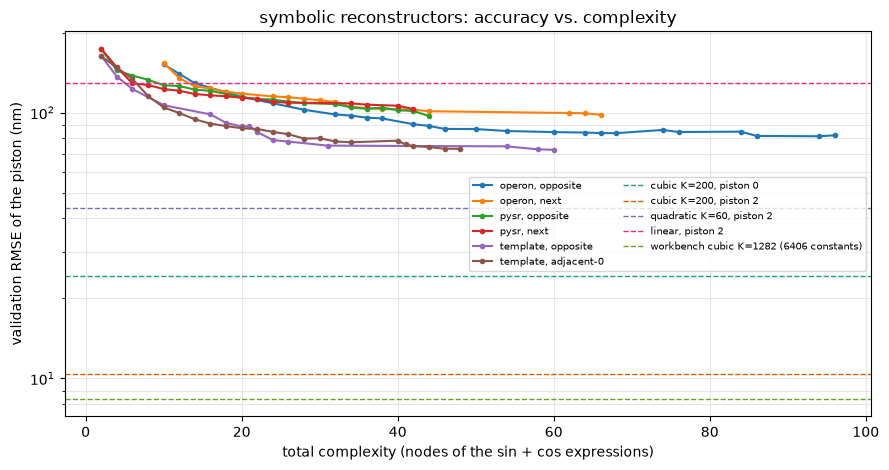

In [22]:
fronts_t = {}
for cls in ("opposite", "adjacent-0"):
    path = f"{SR_DIR}/pysr-template_{cls}.npz"
    if os.path.exists(path):
        with np.load(path) as f:
            fronts_t[f"template, {cls}"] = sy.sr_front_template({k: f[k] for k in f.files}, LAM)
for label, f in fronts_t.items():
    print(label); display(f[["complexity", "constants", "es_rmse", "val_rmse"]].round(2).tail(8))
sy.plot_sr_fronts({**{k: v for k, v in fronts.items() if "opposite" in k or "next" in k}, **fronts_t}, refs)

Scoring the decoded phase directly helps, but only modestly. At complexity
up to about 60 (around 30 constants), the template reaches 72.5 nm for the
opposite piston and 73.1 nm for piston 0, against about 80 nm when sine and
cosine are fitted separately (section 4). That is still far from the
polynomials, let alone the inversion.

### 8c. Assessment

Over the full +-300 nm range, explicit expressions of moderate complexity
have stopped near 70-80 nm. The plain search, Operon, the atan2 template and
the symmetry-adapted features all end up there. Polynomials need thousands of
terms for below 10 nm. The limit looks structural, not a matter of search
effort or library:

- **There is no compact inverse.** The inverse undoes a trigonometric map
  that folds over +-0.75 pi of phase. Near the folds (`piston2.ipynb`) it
  changes quickly, and any smooth compact expression is wrong there.
  Section 5 shows the error falling quickly as the range shrinks, which is
  what a folding map predicts.
- **More search gives small gains.** Fitting the right quantity (the
  template) and running longer moved the front from about 80 to about 72 nm.
  Hours instead of minutes, or a larger maximum size, would improve it
  further, but not by the factor of 10 or more needed to compete.
- **Other libraries are unlikely to change this.**
  - *Genetic programming* (gplearn) is slower than PySR and Operon, which
    are among the strongest engines on the SRBench benchmarks.
  - *Deep symbolic optimisation* (DSO / uDSR) is competitive at a few
    variables, but not better in 19 dimensions.
  - *Pretrained transformer regressors* (E2E, NeSymReS) handle at most
    about 10 input variables, against 19 here.
  - *AI Feynman* looks for separability and symmetries; this inverse is not
    separable.
  - *SISSO and FFX* do sparse regression over generated features, which the
    OMP polynomials of section 3 already approximate.

  None of them can find a short closed form that does not exist.

What does work, and could be pursued:

1. **Smaller ranges.** In closed loop, compact expressions are good (section
   6: 4-8 constants, 2.6-4.2 nm at +-100 nm), and a linear map is enough
   below +-50 nm. A longer search there would likely shrink them further.
2. **An explicit start plus a few Newton steps** (section 8a). The start
   only has to land in the right basin. A compact symbolic start of about
   70 nm does not, for every case. But the staged procedure of section 7c
   detects and fixes its failures from the residual, so "8-constant start +
   Gauss-Newton with restarts" works, at the cost of restarts for a minority
   of cases.
3. **Several wavelengths.** Each wavelength has its own closed form, and
   wavelengths that unfold each other's folds may make the joint inverse
   simpler. That is untested here.

**Recommendation.** Use the closed form for the physics and the inversion,
and compact symbolic expressions for the small-residual, closed-loop
regime. Searching harder for a single compact explicit formula over the full
+-300 nm range is unlikely to pay off.

## 9. Conclusions

**The closed form.** At one wavelength and for petal pistons, the lantern's
response is an exact closed form. Each output signal is a ratio of two
linear combinations of cos and sin of the 15 pairwise petal phase
differences, with 619 constants in all (section 7a). It follows from the
linearity of the PSF and of the lantern in the petal phasors, and it
reproduces the full simulation to numerical precision.

**The reconstructors**, ranked:

| reconstructor | constants | +-300 nm | +-100 nm |
|---|---|---|---|
| inversion of the closed form (Gauss-Newton) | 619 (+ first estimate) | exact; 0.9 nm at 1% noise | exact |
| workbench cubic K=1282 + 3 Gauss-Newton steps (section 8) | 6406 + 619 | exact; all cases within 1 nm (2 steps: 99.97%, RMSE 0.02 nm) | - |
| workbench cubic OMP, K = 1282 | 6406 | 8.4 nm (median 4.7) | - |
| explicit symbolic expression (PySR) | 4-8 per piston | ~80 nm | 2.6-4.2 nm |
| sparse quadratic polynomial | 155 | 81 nm | 3.1 nm |
| linear | 100 | 100 nm | 6.2 nm |
| MLP ensemble (workbench Part C) | 5 x 204k | 6.7 nm (median 0.3) | - |

- **Acquisition over the full +-300 nm range.** Solve the closed form:
  quadratically convergent Gauss-Newton from a good first estimate, with
  twin and random restarts flagged by the residual. It is exact without
  noise, robust to noise up to a few percent, and calibrated from about 100
  known configurations.
- **Closed loop, small residuals.** Explicit expressions work: a linear map
  below +-50 nm, and compact symbolic expressions (4-8 constants) at
  +-100 nm.
- **What limits both.** The low-order aberrations the piston-only models
  leave out: about 0.6 nm of piston error per nm RMS. Extending the closed
  form to them is the natural next step.